In [2]:
# assign directory
import git
from pathlib import Path
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
ROOT_DIR = Path(git.Repo('.', search_parent_directories=True).working_tree_dir)
os.chdir(os.path.join(ROOT_DIR, "utilities"))
from transform_audio import *
os.chdir(os.path.join(ROOT_DIR, "dataset-preparation"))

DATA = 'accent'
accent_dir = os.path.join(ROOT_DIR, 'raw-data', DATA)

data_dir = os.path.join(accent_dir, f'full-{DATA}-audio-processed-trimmed')

file_list = [os.path.join(data_dir, filename) for filename in os.listdir(data_dir) if filename.endswith('.wav')]
file_names = [name for name in os.listdir(data_dir) if name.endswith('.wav')]

csv_path = os.path.join(accent_dir, f'full-{DATA}.csv')
if os.path.exists(csv_path):
    metadata_df = pd.read_csv(csv_path)
    print(f"✅ Metadata loaded: {len(metadata_df)} rows")

print(f"✅ Found {len(file_names)} processed audio files in: {data_dir}")

✅ Metadata loaded: 1537 rows
✅ Found 1537 processed audio files in: /Users/jiaxin/Documents/Summer 2025/hierarchical-bayesian-model-validation/raw-data/accent/full-accent-audio-processed-trimmed


In [3]:
print("Sampling Rate Distributio:")
print(metadata_df['rate (Hz)'].value_counts())

Sampling Rate Distributio:
rate (Hz)
16000    1537
Name: count, dtype: int64


/Users/jiaxin/Documents/Summer 2025/hierarchical-bayesian-model-validation/.conda/lib/python3.11/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/jiaxin/Documents/Summer 2025/hierarchical-bayesian-model-validation/.conda/lib/python3.11/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/jiaxin/Documents/Summer 2025/hierarchical-bayesian-model-validation/.conda/lib/python3.11/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


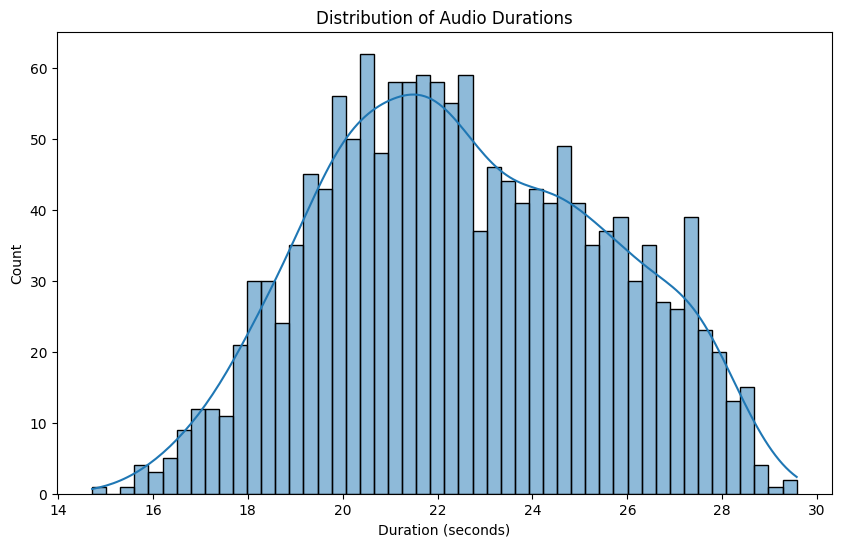

In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(metadata_df['length (s)'], bins=50, kde=True)
plt.title('Distribution of Audio Durations')
plt.xlabel('Duration (seconds)')
plt.show()

/var/folders/73/sgjz9s7d6b318g3bz68k4lnr0000gn/T/ipykernel_7773/2696577515.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_accent, x='sex', ax=axes[0], palette='pastel')
/var/folders/73/sgjz9s7d6b318g3bz68k4lnr0000gn/T/ipykernel_7773/2696577515.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_accent, x='is_native_english', ax=axes[1], palette='magma')


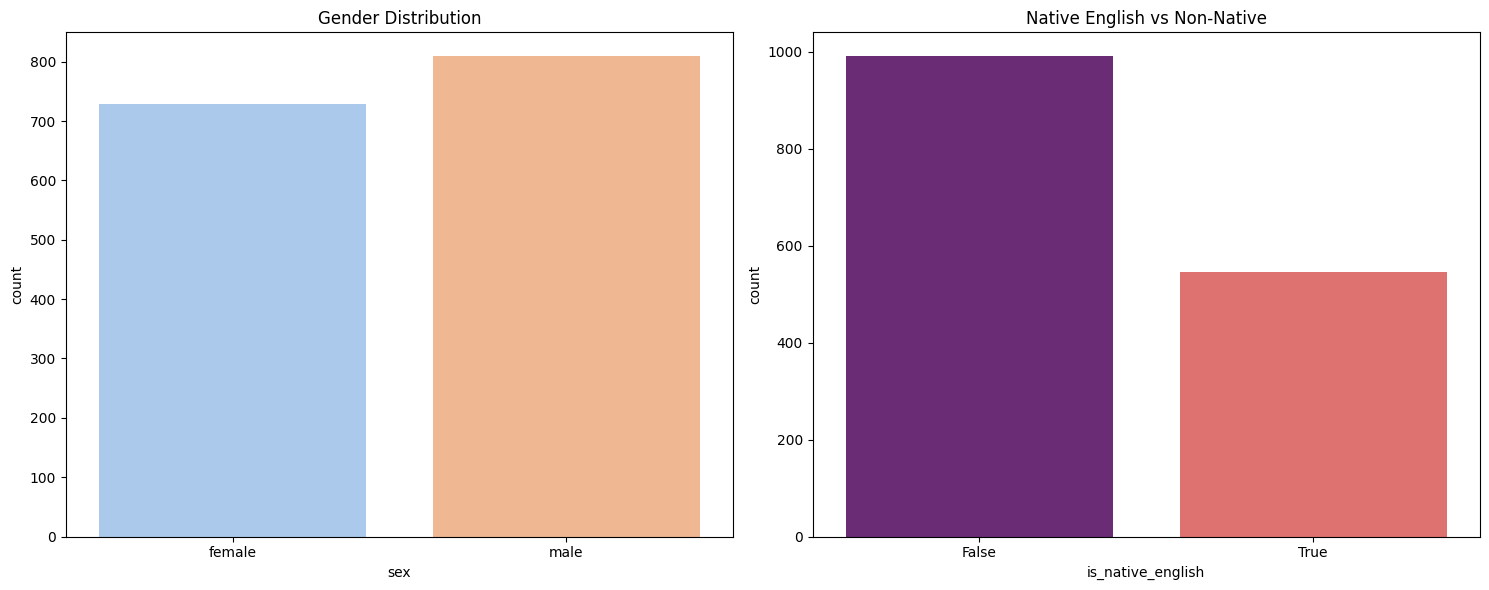

In [8]:
from scipy.io import wavfile
df_accent = pd.read_csv(os.path.join(ROOT_DIR, 'raw-data', 'accent', 'full-accent.csv'))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.countplot(data=df_accent, x='sex', ax=axes[0], palette='pastel')
axes[0].set_title('Gender Distribution')

sns.countplot(data=df_accent, x='is_native_english', ax=axes[1], palette='magma')
axes[1].set_title('Native English vs Non-Native')

plt.tight_layout()
plt.show()

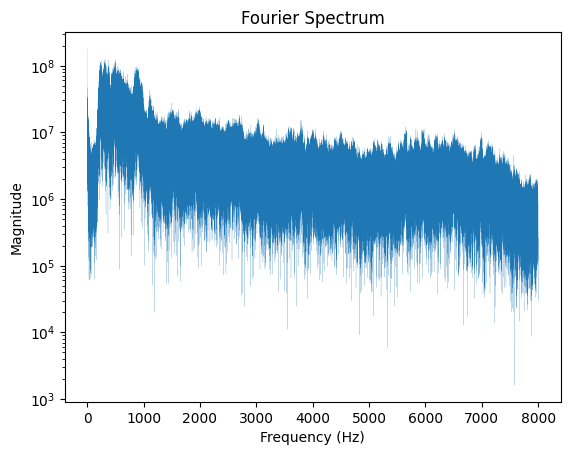

In [4]:
fft_file(file_list[0], discard_negative=True, visualize=True);

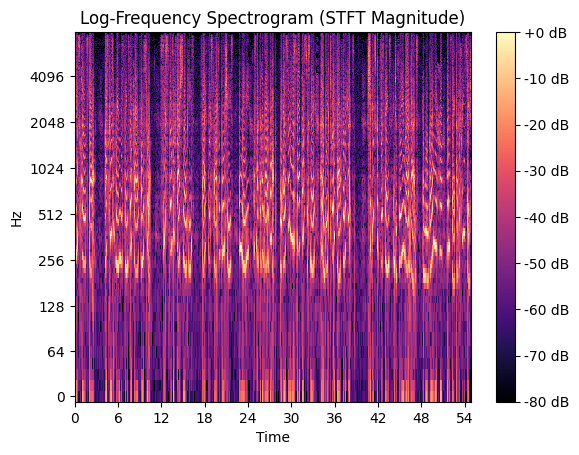

In [7]:
stft_file(file_list[0], visualize=True);

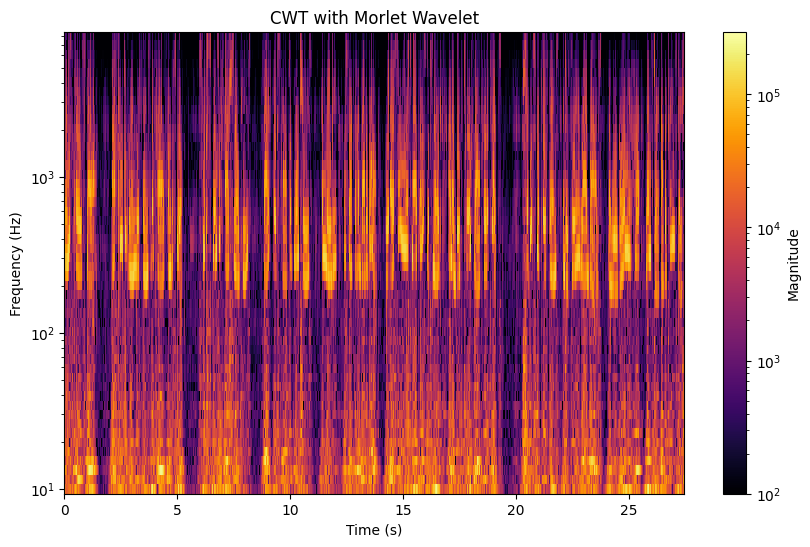

In [8]:
coefs, freqs = cwt_file(file_list[0],
                        low_freq=10,
                        high_freq=8000,
                        num_scales=50, 
                        visualize=True);